# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [ ]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("datasnaek/chess")

print("Path to dataset files:", path)

df = pd.read_csv(os.path.join(path, 'games.csv'))

df.head()

Using Colab cache for faster access to the 'chess' dataset.
Path to dataset files: /kaggle/input/chess


,id,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply
0,TZJHLljE,False,1.504210e+12,1.504210e+12,13,outoftime,white,15+2,bourgris,1500,a-00,1191,d4 d5 c4 c6 cxd5 e6 dxe6 fxe6 Nf3 Bb4+ Nc3 Ba5...,D10,Slav Defense: Exchange Variation,5
1,l1NXvwaE,True,1.504130e+12,1.504130e+12,16,resign,black,5+10,a-00,1322,skinnerua,1261,d4 Nc6 e4 e5 f4 f6 dxe5 fxe5 fxe5 Nxe5 Qd4 Nc6...,B00,Nimzowitsch Defense: Kennedy Variation,4
2,mIICvQHh,True,1.504130e+12,1.504130e+12,61,mate,white,5+10,ischia,1496,a-00,1500,e4 e5 d3 d6 Be3 c6 Be2 b5 Nd2 a5 a4 c5 axb5 Nc...,C20,King's Pawn Game: Leonardis Variation,3
3,kWKvrqYL,True,1.504110e+12,1.504110e+12,61,mate,white,20+0,daniamurashov,1439,adivanov2009,1454,d4 d5 Nf3 Bf5 Nc3 Nf6 Bf4 Ng4 e3 Nc6 Be2 Qd7 O...,D02,Queen's Pawn Game: Zukertort Variation,3
4,9tXo1AUZ,True,1.504030e+12,1.504030e+12,95,mate,white,30+3,nik221107,1523,adivanov2009,1469,e4 e5 Nf3 d6 d4 Nc6 d5 Nb4 a3 Na6 Nc3 Be7 b4 N...,C41,Philidor Defense,5


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Heart Disease tem 13 variáveis preditoras (idade, sexo, tipo de dor no peito, pressão em repouso, colesterol, entre outras) mais o alvo (`num`, presença/grau de doença cardíaca). Quantas linhas vocês esperam que um dataset clínico como esse tenha — dezenas, centenas ou milhares de pacientes?

### Dimensão e Tipos de Dados

In [ ]:
df.shape

(20058, 16)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 19629 entries, 0 to 20057
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              19629 non-null  object 
 1   rated           19629 non-null  bool   
 2   created_at      19629 non-null  float64
 3   last_move_at    19629 non-null  float64
 4   turns           19629 non-null  int64  
 5   victory_status  19629 non-null  object 
 6   winner          19629 non-null  object 
 7   increment_code  19629 non-null  object 
 8   white_id        19629 non-null  object 
 9   white_rating    19629 non-null  int64  
 10  black_id        19629 non-null  object 
 11  black_rating    19629 non-null  int64  
 12  moves           19629 non-null  object 
 13  opening_eco     19629 non-null  object 
 14  opening_name    19629 non-null  object 
 15  opening_ply     19629 non-null  int64  
dtypes: bool(1), float64(2), int64(4), object(9)
memory usage: 2.4+ MB


In [ ]:
df.describe()

,created_at,last_move_at,turns,white_rating,black_rating,opening_ply
count,2.005800e+04,2.005800e+04,20058.000000,20058.000000,20058.000000,20058.000000
mean,1.483617e+12,1.483618e+12,60.465999,1596.631868,1588.831987,4.816981
std,2.850151e+10,2.850140e+10,33.570585,291.253376,291.036126,2.797152
min,1.376772e+12,1.376772e+12,1.000000,784.000000,789.000000,1.000000
25%,1.477548e+12,1.477548e+12,37.000000,1398.000000,1391.000000,3.000000
50%,1.496010e+12,1.496010e+12,55.000000,1567.000000,1562.000000,4.000000
75%,1.503170e+12,1.503170e+12,79.000000,1793.000000,1784.000000,6.000000
max,1.504493e+12,1.504494e+12,349.000000,2700.000000,2723.000000,28.000000


### Duplicadas

In [ ]:
df.duplicated().sum()
df.drop_duplicates(inplace=True)
df.duplicated().sum()


np.int64(0)

### Renomeando o atributo alvo para facilitar a interpretação

O dataset original registra `num` de 0 (sem doença) a 4 (graus diferentes de doença). Pra hoje, vamos simplificar para uma variável binária, presença ou ausência de doença cardíaca, já que é essa a distinção que vamos usar nas cores ao longo da aula (rosa = sem doença, roxo = com doença).

In [ ]:
# O dataset original registra `winner` com três valores: white, black, draw.
# Pra hoje, vamos simplificar para uma variável binária, vitória das brancas ou não,
# já que é essa a distinção que vamos usar nas cores ao longo da aula (rosa = não venceu, roxo = brancas venceram).

df["brancas_venceram"] = np.where(df["winner"] == "white", "Brancas venceram", "Outro resultado")
df["brancas_venceram"].value_counts()
df.drop(columns=["winner"], inplace=True)
df.head()

,id,rated,created_at,last_move_at,turns,victory_status,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply,brancas_venceram
0,TZJHLljE,False,1.504210e+12,1.504210e+12,13,outoftime,15+2,bourgris,1500,a-00,1191,d4 d5 c4 c6 cxd5 e6 dxe6 fxe6 Nf3 Bb4+ Nc3 Ba5...,D10,Slav Defense: Exchange Variation,5,Brancas venceram
1,l1NXvwaE,True,1.504130e+12,1.504130e+12,16,resign,5+10,a-00,1322,skinnerua,1261,d4 Nc6 e4 e5 f4 f6 dxe5 fxe5 fxe5 Nxe5 Qd4 Nc6...,B00,Nimzowitsch Defense: Kennedy Variation,4,Outro resultado
2,mIICvQHh,True,1.504130e+12,1.504130e+12,61,mate,5+10,ischia,1496,a-00,1500,e4 e5 d3 d6 Be3 c6 Be2 b5 Nd2 a5 a4 c5 axb5 Nc...,C20,King's Pawn Game: Leonardis Variation,3,Brancas venceram
3,kWKvrqYL,True,1.504110e+12,1.504110e+12,61,mate,20+0,daniamurashov,1439,adivanov2009,1454,d4 d5 Nf3 Bf5 Nc3 Nf6 Bf4 Ng4 e3 Nc6 Be2 Qd7 O...,D02,Queen's Pawn Game: Zukertort Variation,3,Brancas venceram
4,9tXo1AUZ,True,1.504030e+12,1.504030e+12,95,mate,30+3,nik221107,1523,adivanov2009,1469,e4 e5 Nf3 d6 d4 Nc6 d5 Nb4 a3 Na6 Nc3 Be7 b4 N...,C41,Philidor Defense,5,Brancas venceram


## 2. Dados Faltantes

In [ ]:
df.isna().sum()

,0
id,0
rated,0
created_at,0
last_move_at,0
turns,0
victory_status,0
increment_code,0
white_id,0
white_rating,0
black_id,0


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: *-Não*

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual não há features com dados ausentes — df.isna().sum() retorna 0 para todas as colunas.

Como os dados foram coletados:

- O conjunto de dados foi extraído via API do Lichess (plataforma de xadrez online) e reúne registros de partidas jogadas por usuários da plataforma.
- Diferente de bases construídas a partir de múltiplos estudos independentes, este dataset tem uma única origem: os logs do próprio sistema do Lichess.

Qual a natureza da fonte de dados:

- Por se tratar de um log gerado automaticamente pelo sistema no momento em que cada partida ocorre e termina, não há dependência de preenchimento manual, formulários ou exames sujeitos a custo, desistência ou indisponibilidade — como ocorre em estudos que envolvem pessoas (ex.: pacientes médicos).
- Cada atributo (jogadores, ratings, número de lances, resultado, abertura jogada) é registrado diretamente pela plataforma no instante da partida, o que explica a completude dos dados.
- Isso evidencia que a natureza da fonte — um log de sistema de uma plataforma digital — é estruturalmente diferente de datasets clínicos multi-institucionais, onde a ausência de dados costuma refletir limitações humanas ou logísticas da coleta.

*USEI o Claude(Sonnet 5) para suporte.*

**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



In [ ]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: []
Series([], dtype: float64)


Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

In [ ]:
tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
            rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

IndexError: list index out of range

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, o paciente não fez o exame porque já se suspeitava (por sinais clínicos observados previamente) que o resultado seria anormal, e o exame extra não seria necessário, isso seria classificado como **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, o protocolo de coleta decidiu não solicitar aquele exame, ou o custo do procedimento limitou a coleta, independente do que o resultado provavelmente seria — isso seria classificado como **MAR** (ou até **MCAR**, se a decisão for arbitrária e não sistemática).

Não dá pra decidir entre as duas só olhando os dados — é exatamente o tipo de situação em que testes estatísticos (como o teste de MCAR) e conhecimento de domínio real (falar com quem coletou os dados) resolveriam a dúvida. Na ausência disso, seguimos com a opção mais conservadora na hora de tratar.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [ ]:
VARS_QUANT = ["turns", "white_rating", "black_rating", "opening_ply"]
VARS_QUALI = ["rated", "victory_status", "brancas_venceram", "opening_eco"]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
turns,60.46,55.00,33.50,1.00,349.00,0.88,1.17
white_rating,1596.09,1567.00,290.17,784.00,2700.00,0.30,0.03
black_rating,1588.32,1562.00,290.16,789.00,2723.00,0.25,-0.05
opening_ply,4.80,4.00,2.79,1.00,28.00,1.34,3.14


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

Isso é coerente com o que vocês esperariam fisiologicamente (ex: colesterol e pressão em repouso costumam ter poucos pacientes com valores muito altos, puxando a cauda direita)?


**Resposta:** Olhando a tabela, as variáveis que mais se destacam são `turns` (skewness 0,88, próximo do limite, e kurtosis 1,17) e principalmente `opening_ply` (skewness 1,34 e kurtosis 3,14, os valores mais altos entre todas), indicando cauda mais pesada e distribuição bem mais assimétrica que as demais. Já `white_rating` e `black_rating` têm skewness bem baixo (0,30 e 0,25) e kurtosis próxima de zero, sugerindo distribuições bem mais próximas de uma normal — o que faz sentido, já que sistemas de rating (como o do Lichess) são desenhados justamente para produzir uma distribuição aproximadamente normal na população de jogadores. A assimetria de `turns` também é coerente com a lógica do jogo: a maioria das partidas termina num número "razoável" de lances, mas existe uma cauda de partidas muito longas (finais complexos, jogadores cautelosos) que não tem um limite superior natural, puxando a média para cima em relação à mediana. Já `opening_ply` ser a mais assimétrica faz sentido porque a maior parte das partidas segue teoria de abertura só por poucos lances antes de "sair do livro", enquanto uma minoria de partidas (geralmente entre jogadores mais fortes) segue linhas de abertura decoradas por muito mais lances.

### Distribuições de dados

Onde fizer sentido, comparamos "Sem doença" (rosa) vs. "Com doença" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


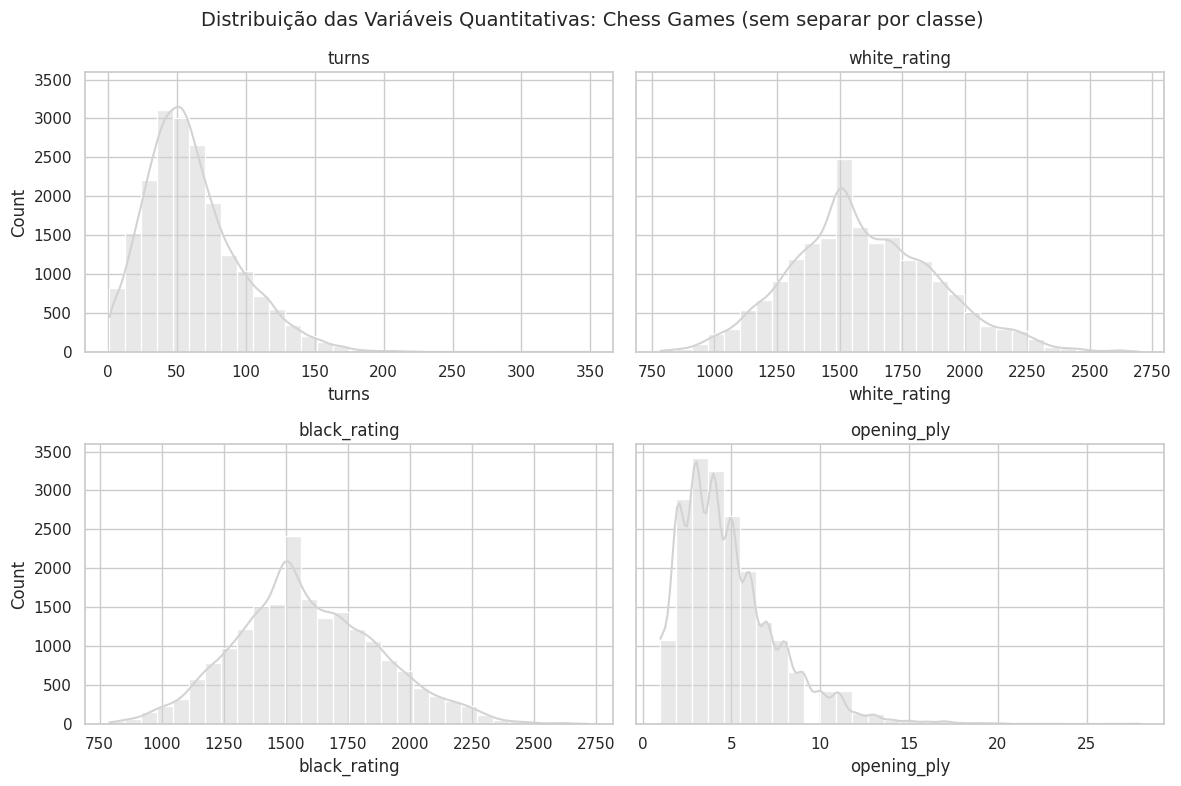

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i], bins=30)
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: Chess Games (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()

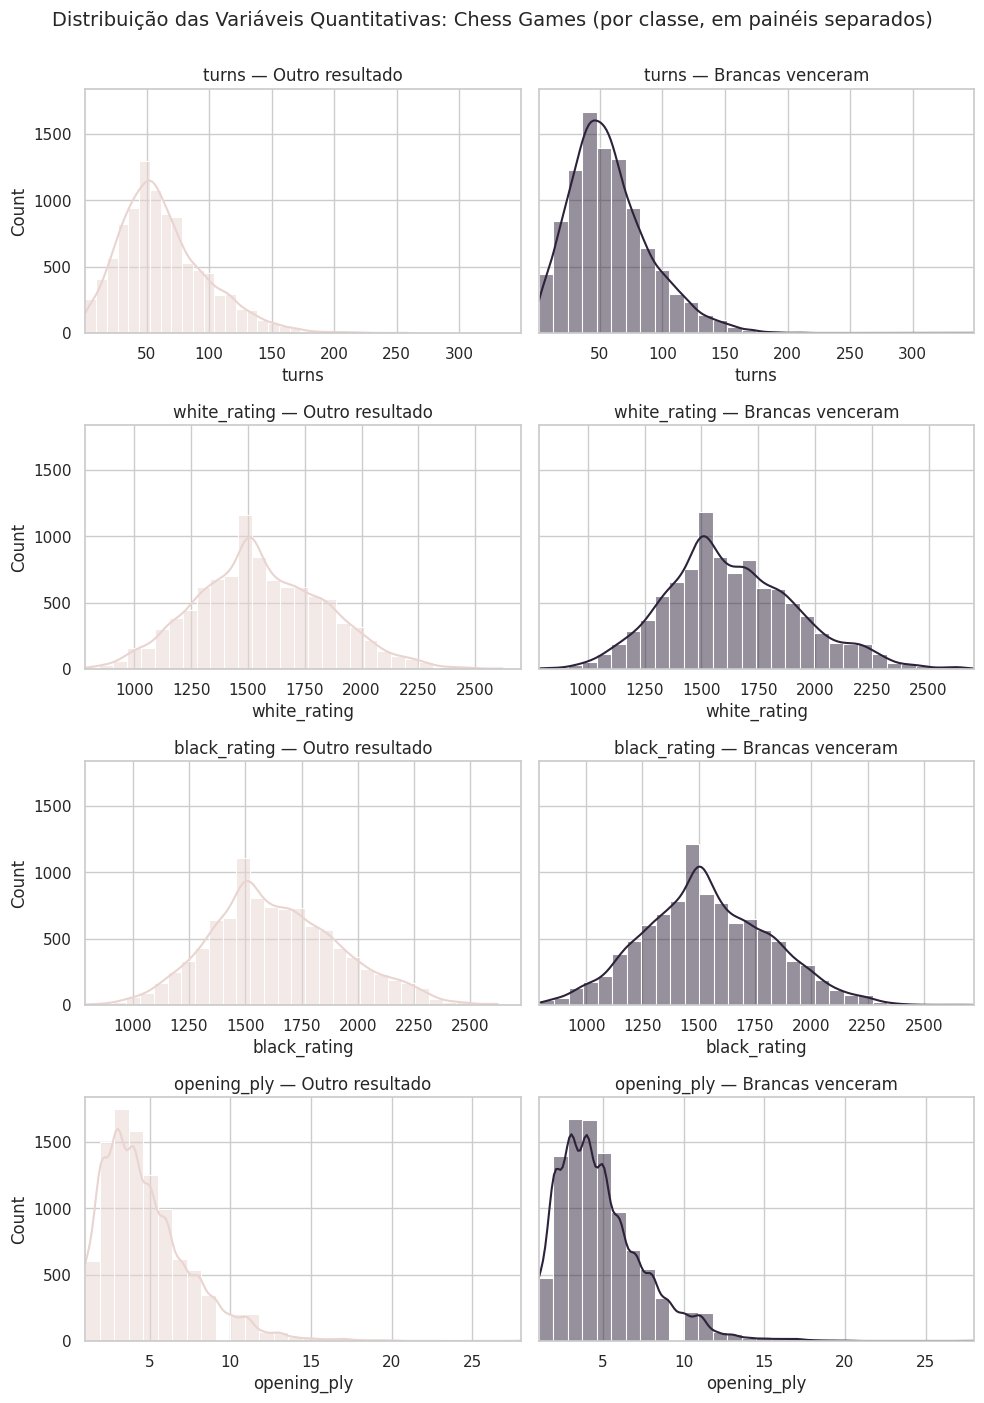

In [ ]:
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=True)

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate([("Outro resultado", COR_CONTEXTO), ("Brancas venceram", COR_DESTAQUE)]):
        subset = df[df["brancas_venceram"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j], bins=30)
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das Variáveis Quantitativas: Chess Games (por classe, em painéis separados)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Normal" e "Cardíaco"?

**Resposta:** Olhando os painéis lado a lado, white_rating e black_rating são as variáveis que mais chamam atenção: nos dois casos, o painel "Brancas venceram" parece deslocado para a direita em relação a "Outro resultado", especialmente no rating das brancas — o que faz sentido, já que jogadores com rating mais alto tendem a vencer com mais frequência independente da cor. Já turns e opening_ply parecem manter um formato bastante parecido entre as duas classes, sem um deslocamento visual óbvio no centro da distribuição — sugerindo que o número de lances ou de lances de abertura, isoladamente, não diferencia tanto quem venceu a partida quanto o rating diferencia. Isso é coerente com a lógica do jogo: rating é uma medida direta de força do jogador (e portanto uma influência direta no resultado), enquanto duração da partida ou profundidade de abertura são mais uma consequência do estilo de jogo do que uma causa do resultado.

#### Testes de Aderência

*Será se o rating das brancas segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `white-rating`.

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 19629.
  res = hypotest_fun_out(*samples, **kwds)


Shapiro-Wilk — white_rating: estatística=0.9938, p-valor=7.547e-28
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


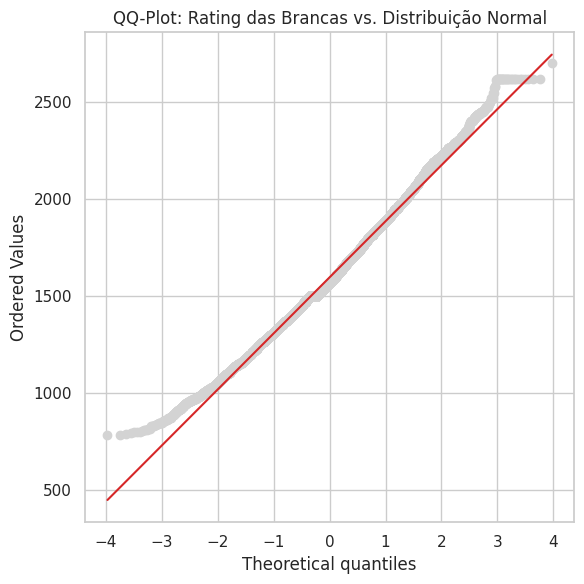

In [ ]:
stat_sw, p_valor_sw = stats.shapiro(df["white_rating"].dropna())
print(f"Shapiro-Wilk — white_rating: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

"""### QQ-Plot — rating das brancas"""

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["white_rating"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Rating das Brancas vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade — é o contrário. Amostras pequenas têm menos poder estatístico, ou seja, tendem a não rejeitar mesmo quando os dados realmente não são normais. Já amostras muito grandes (milhares de linhas, como é o nosso caso aqui, com n na casa dos milhares de partidas) deixam o teste sensível demais, rejeitando a normalidade mesmo por desvios pequenos e sem relevância prática. Por isso, com esse n grande, uma rejeição do Shapiro-Wilk sozinha não é tão conclusiva quanto seria numa amostra moderada — vale sempre cruzar com o QQ-Plot e a skewness/kurtosis (que no caso de white_rating são bem próximas de zero) pra avaliar se o desvio observado é realmente substancial ou só estatisticamente detectável por causa do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste rejeita H0 (p < 0.05), a afirmação correta é "temos evidência estatística contra a normalidade" — mas em amostras grandes vale qualificar isso com o tamanho do desvio visto no QQ-Plot/skewness, já que a rejeição isolada pode refletir o n, não necessariamente um afastamento prático da normal. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste não rejeita H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

In [ ]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 19629.
  res = hypotest_fun_out(*samples, **kwds)


,estatistica,p_valor,rejeita_normalidade
variavel,,,
turns,0.9572,0.0,True
white_rating,0.9938,0.0,True
black_rating,0.9950,0.0,True
opening_ply,0.9002,0.0,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`white_ratingl`, rating das brancas), só pra fixar como essa visualização se lê.

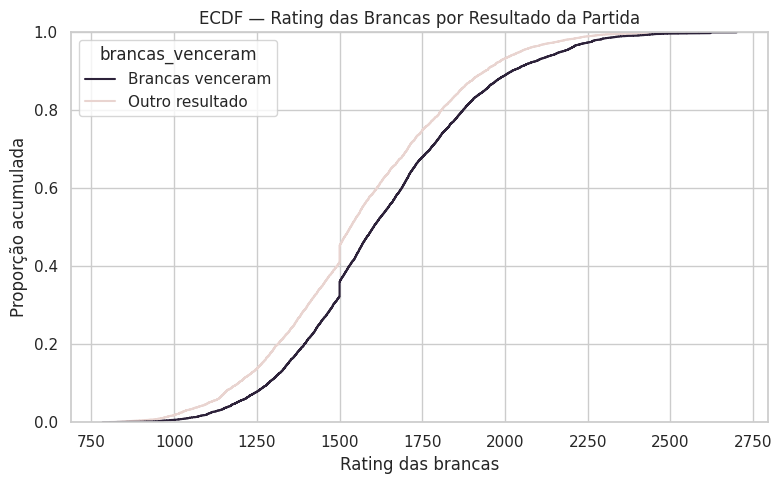

In [ ]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="white_rating", hue="brancas_venceram",
             palette={"Outro resultado": COR_CONTEXTO, "Brancas venceram": COR_DESTAQUE})
plt.title("ECDF — Rating das Brancas por Resultado da Partida")
plt.xlabel("Rating das brancas")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração das partidas desse grupo tem rating das brancas até aqui". Onde as duas curvas (rosa e roxa) se distanciam mais, ali está a faixa de rating onde os dois grupos mais diferem, sem precisar decidir uma largura de bin como no histograma.

### Métricas de Tendêncial Central

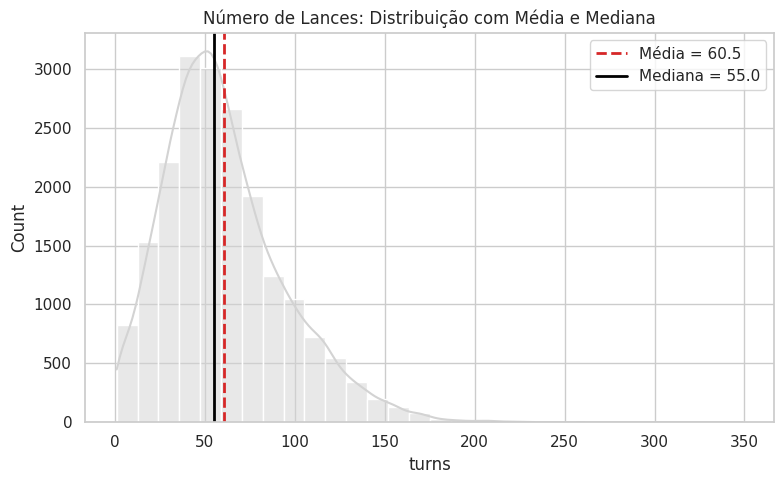

In [ ]:
media_turns = df["turns"].mean()
mediana_turns = df["turns"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="turns", kde=True, color=COR_NEUTRA, bins = 30)
plt.axvline(media_turns, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_turns:.1f}")
plt.axvline(mediana_turns, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_turns:.1f}")
plt.title("Número de Lances: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

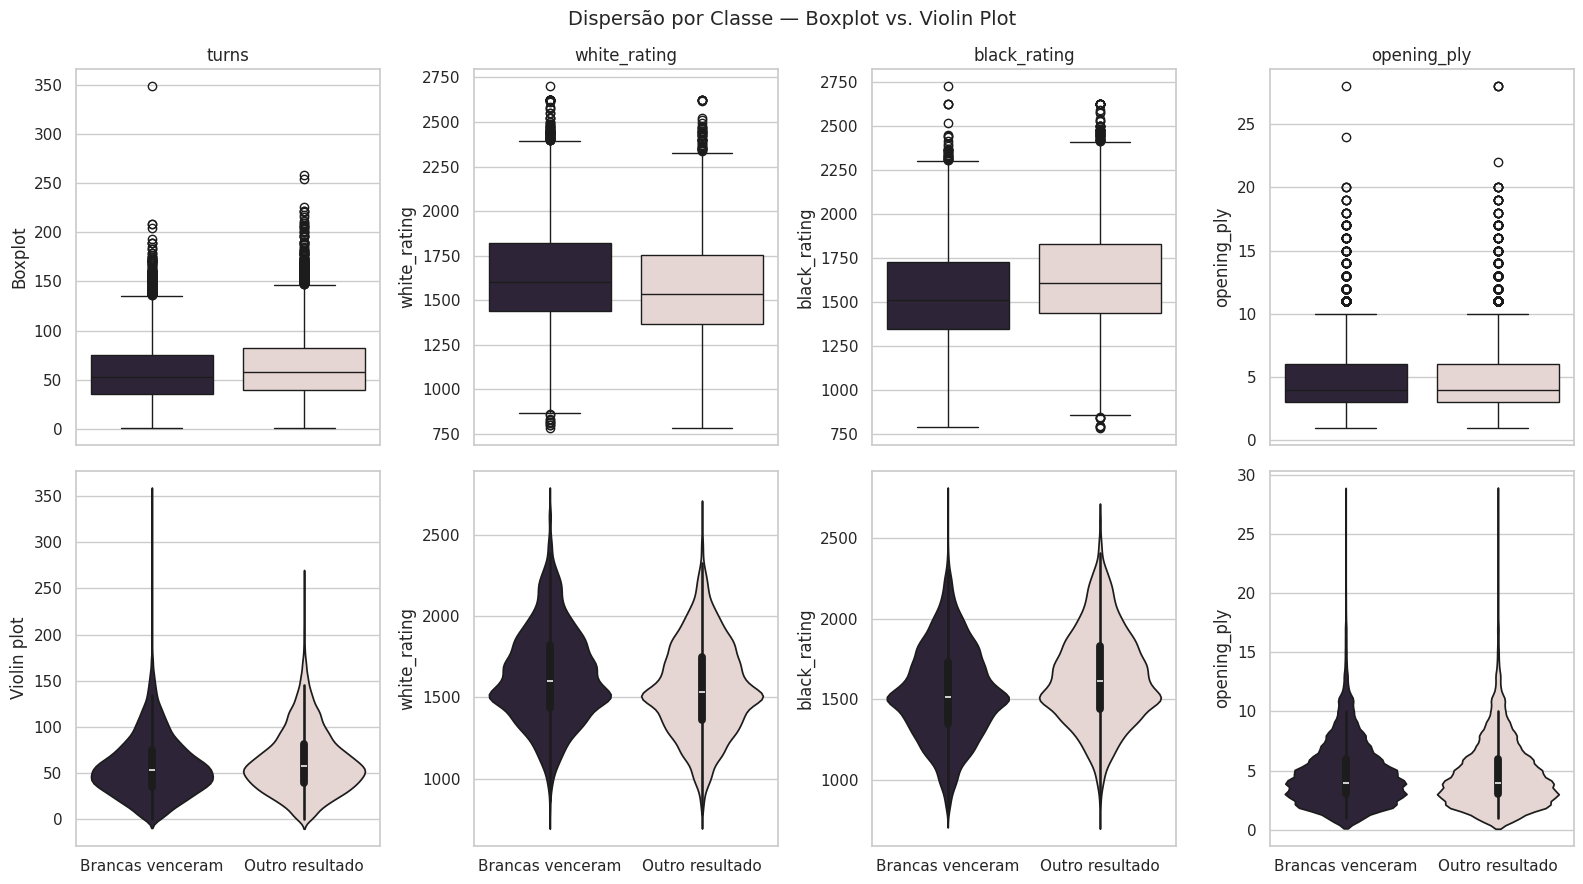

In [ ]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

"""### Boxplot e violin plot por classe"""

palette_classe = {"Outro resultado": COR_CONTEXTO, "Brancas venceram": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="brancas_venceram", y=col, hue="brancas_venceram",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="brancas_venceram", y=col, hue="brancas_venceram",
                    palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Outro resultado" e "Brancas venceram"? Isso já é um indício, antes mesmo da análise bivariada formal, de que essa variável pode ajudar a diferenciar as duas classes.

**Resposta:** Olhando os gráficos, white_rating deve ser a variável com maior diferença: partidas com "Brancas venceram" tendem a ter rating das brancas mais alto, o que já é um bom indício pra separar as classes. black_rating pode mostrar um padrão parecido, só que invertido. Já turns e opening_ply não devem variar muito entre os dois grupos, já que a duração da partida ou a abertura jogada dependem mais do estilo dos jogadores do que de quem venceu.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`ca`, `thal`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
turns,-26.0,142.0,420.0
white_rating,813.5,2377.5,135.0
black_rating,808.0,2368.0,94.0
opening_ply,-1.5,10.5,876.0


### Visualizando os Outliers

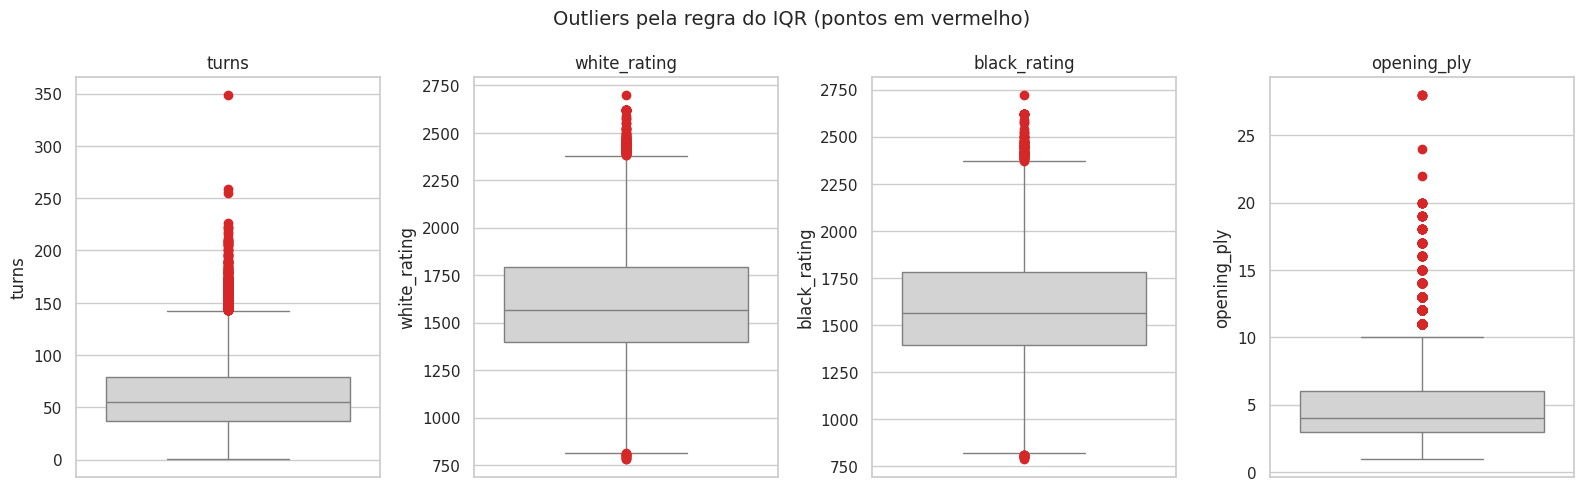

In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados, principalmente em turns e opening_ply: eles parecem estrategicamente plausíveis (partidas reais podem se estender por muitos lances, ou terminar rápido por um abandono), ou parecem violar algum limite conhecido das regras do xadrez? Isso muda qual das três categorias se aplica e, consequentemente, se devemos manter, transformar ou remover.

Na prática, os outliers de turns acima do limite superior são plausíveis: partidas com centenas de lances acontecem, especialmente entre jogadores cautelosos ou em finais complexos, então esse caso se encaixa como outlier estatístico (legítimo). Já os outliers de opening_ply merecem mais cuidado: valores muito altos podem representar partidas em que os jogadores seguiram teoria de abertura decorada por muitos lances, o que também é plausível, mas vale checar se algum valor extremo excede o próprio turns da partida, o que indicaria um erro de dado em vez de um outlier legítimo.

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que já discutimos: o mecanismo mais provável para `ca`/`thal` é MAR ou MCAR (não MNAR), e o volume é pequeno (poucas linhas em ~300). Com essas duas informações juntas, a decisão pragmática é remover as linhas afetadas — o risco de viés é baixo (mecanismo provavelmente não depende do próprio valor ausente) e o custo de perder ~2% das linhas é pequeno.

In [ ]:
print("Dados ausentes por coluna:")
print(df.isna().sum().sum(), "valores ausentes no total — nenhum tratamento necessário.")

Dados ausentes por coluna:
0 valores ausentes no total — nenhum tratamento necessário.


### Decidindo o Tratamento dos Outliers

Diferente de um cenário com dados ausentes, aqui não vamos remover automaticamente. Pelos valores encontrados em `turns` e `opening_ply` (dentro de faixas plausíveis para o jogo, ainda que raras), a classificação mais provável é "Estatístico", outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é manter (a informação é real e pode ser relevante, por exemplo, partidas com número extremo de lances podem ser justamente os finais mais interessantes de analisar) ou, se for necessário para alguma técnica estatística específica mais à frente (métodos sensíveis à assimetria), transformar.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em `turns`, útil caso, mais adiante em análises futuras, a assimetria atrapalhe algum teste ou modelo.

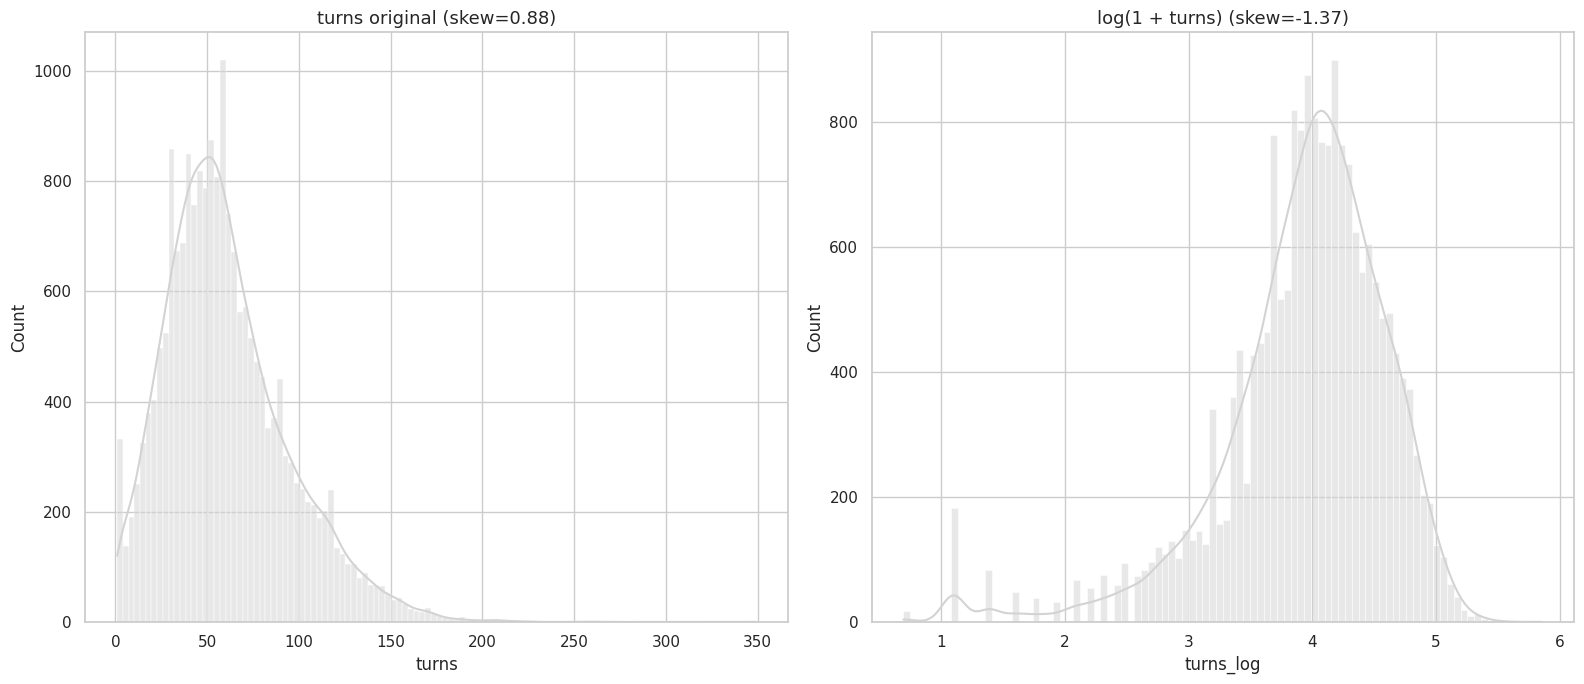

In [ ]:
df["turns_log"] = np.log1p(df["turns"])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sns.histplot(data=df, x="turns", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"turns original (skew={df['turns'].skew():.2f})", fontsize=13)

sns.histplot(data=df, x="turns_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + turns) (skew={df['turns_log'].skew():.2f})", fontsize=13)

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria? Sim, a transformação logarítmica deve reduzir visivelmente a assimetria de turns: o skewness original era 0,88, e o log tende a comprimir a cauda longa à direita (partidas muito longas), aproximando a distribuição de uma forma mais simétrica.

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

**Sobre a classificação dos outliers de turns:** são valores estatisticamente raros mas plausíveis, partidas muito longas ou muito curtas acontecem de fato no xadrez, então a decisão é manter ou transformar, não remover.

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: não havia dados ausentes para tratar, e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [ ]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
turns,60.46,55.00,33.50,1.00,349.00,0.88,1.17
white_rating,1596.09,1567.00,290.17,784.00,2700.00,0.30,0.03
black_rating,1588.32,1562.00,290.16,789.00,2723.00,0.25,-0.05
opening_ply,4.80,4.00,2.79,1.00,28.00,1.34,3.14


### Comparando "antes"x "depois""



In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
turns,0.878,0.878,1.165,1.165,0.0,0.0
white_rating,0.297,0.297,0.030,0.030,0.0,0.0
black_rating,0.252,0.252,-0.051,-0.051,0.0,0.0
opening_ply,1.343,1.343,3.144,3.144,0.0,0.0


**Pra discutir:** os valores mudaram muito? O esperado é que delta_skewness e delta_kurtosis saiam exatamente zero em todas as linhas, já que df não foi alterado entre a Seção 3 e agora (nenhuma linha removida, nenhuma coluna original transformada). Isso é um resultado diferente do dataset médico, onde a remoção de ~2% das linhas ainda podia gerar pequenas mudanças nos valores. Aqui, o "antes x depois" serve mais como confirmação de que a decisão de não tratar nada foi consistente, do que como uma comparação de efeito de tratamento propriamente dita.

**O rating das brancas ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [ ]:
stat_sw, p_valor_sw = stats.shapiro(df["white_rating"].dropna())
print(f"Shapiro-Wilk — white_rating: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

Shapiro-Wilk — white_rating: estatística=0.9938, p-valor=7.547e-28
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (`chol` e `oldpeak`), comparando a versão original (`df_antes`) com a tratada (`df`).

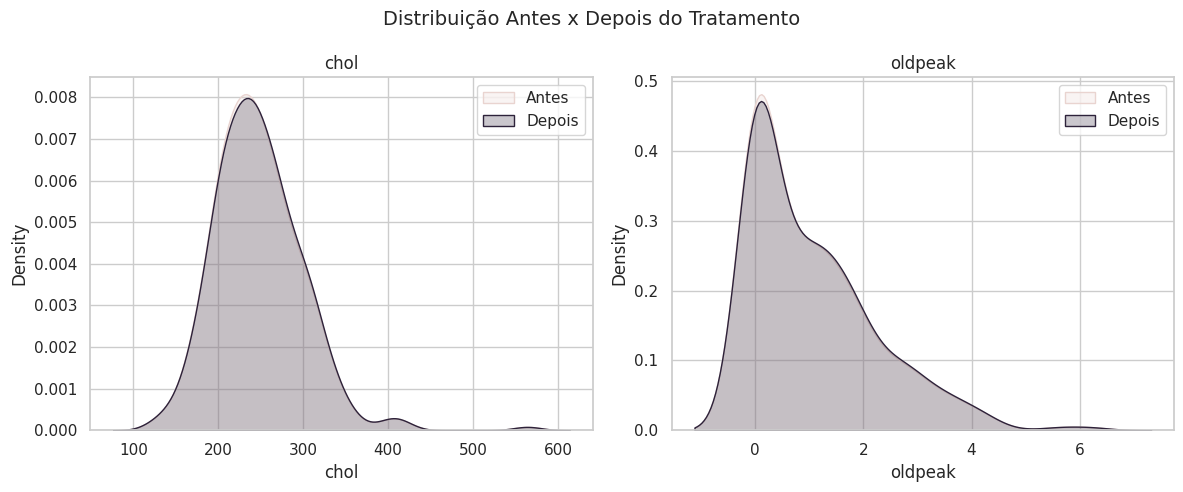

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ["chol", "oldpeak"]):
    sns.kdeplot(df_antes[col], color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

**Resposta:** não há uma comparação "antes x depois" real, já que nenhuma linha foi removida nem nenhum valor original alterado, então as curvas seriam idênticas, não apenas parecidas. Isso é esperado, pois não havia ausentes e optamos por manter os outliers sem transformação. A observação para os outros datasets continua válida: quando o volume de ausentes/outliers for maior, essa checagem pode revelar diferenças reais, e é ela que confirma se o tratamento teve o efeito esperado, em vez de assumir isso sem checar.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [ ]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))

\n--- rated ---
       absoluta  relativa
rated                    
True      15817     0.806
False      3812     0.194
\n--- victory_status ---
                absoluta  relativa
victory_status                    
resign             10926     0.557
mate                6188     0.315
outoftime           1641     0.084
draw                 874     0.045
\n--- brancas_venceram ---
                  absoluta  relativa
brancas_venceram                    
Outro resultado       9837     0.501
Brancas venceram      9792     0.499
\n--- opening_eco ---
             absoluta  relativa
opening_eco                    
A00               992     0.051
C00               824     0.042
D00               719     0.037
B01               707     0.036
C41               671     0.034
...               ...       ...
D58                 1     0.000
C32                 1     0.000
E18                 1     0.000
D95                 1     0.000
D22                 1     0.000

[365 rows x 2 columns]


#### Visualizando as frequências

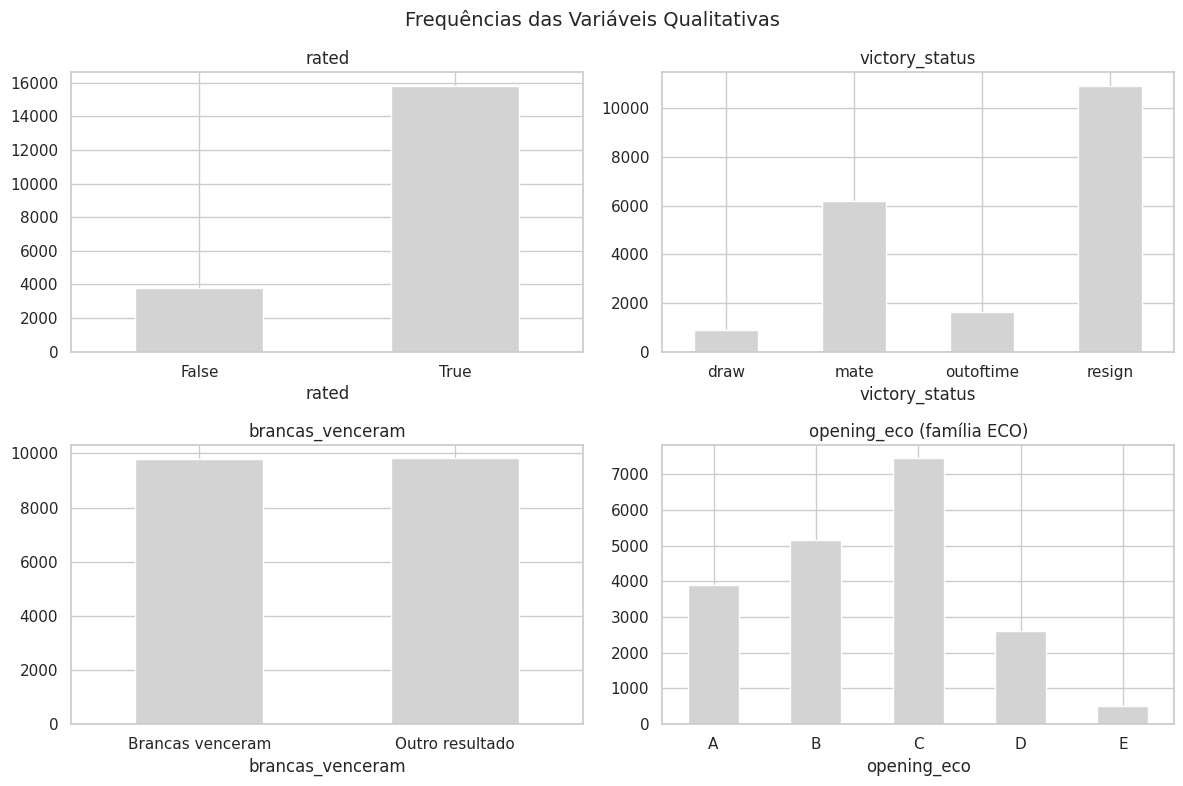

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=False)
axes = axes.ravel()

vars_quali_plot = ["rated", "victory_status", "brancas_venceram"]

for i, col in enumerate(vars_quali_plot):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=0)

df["opening_eco"].str[0].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[3])
axes[3].set_title("opening_eco (família ECO)")
axes[3].tick_params(axis="x", rotation=0)

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

**Resposta:** rated e victory_status devem ser as mais desbalanceadas, provavelmente dominadas por "ranqueada" e "resign", respectivamente. brancas_venceram deve ficar mais equilibrado. Isso importa porque cruzamentos com a categoria minoritária vão ter poucos dados para comparação na análise bivariada.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `doenca_cardiaca`.

In [ ]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
rated,2.0,4.15,0.710
victory_status,4.0,12.50,0.747
brancas_venceram,2.0,1.00,1.000
opening_eco,365.0,992.00,0.782


**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `doenca_cardiaca` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

**Resposta:**

`victory_status` deve ser a mais desbalanceada (dominada por "resign"). O alvo `brancas_venceram` deve ficar bem equilibrado, já que a vantagem de jogar com as brancas é pequena, então não deve distorcer a análise bivariada.

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'doença cardíaca'.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

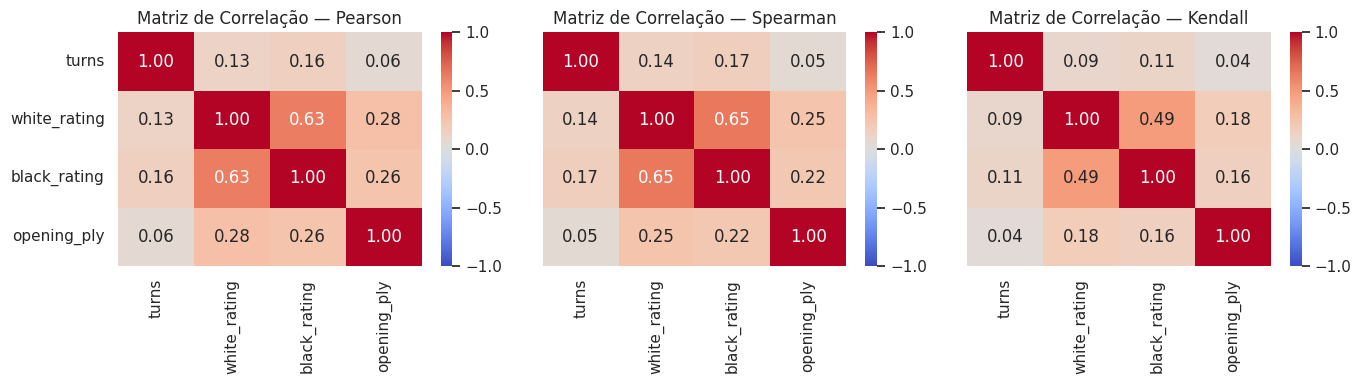

In [ ]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1,3,figsize=(14, 4),sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()


Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

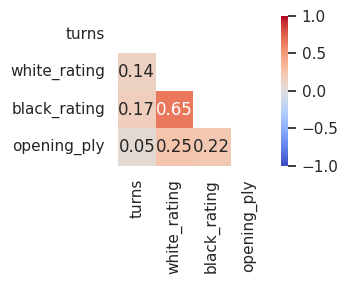

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(4, 3))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,)
plt.grid(False)

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não.

**Resposta:**

`white_rating` x `black_rating` deve mostrar correlação parecida nas três métricas, já que essa relação tende a ser linear (matchmaking por força parecida). Pares com `turns` ou `opening_ply` são mais propensos a divergir, pois são variáveis assimétricas.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `age` x `thalach` por um motivo de domínio, não só estatístico: existe uma relação fisiológica entre idade e frequência cardíaca máxima, o que torna esse par um bom candidato pra visualizar uma tendência real.

**Nota para quando vocês replicarem no dataset de vocês:** nem sempre vai existir uma relação de domínio óbvia e, nesse caso, uma alternativa é escolher o par com o maior |correlação| na tabela acima, deixando a própria estatística guiar a escolha.

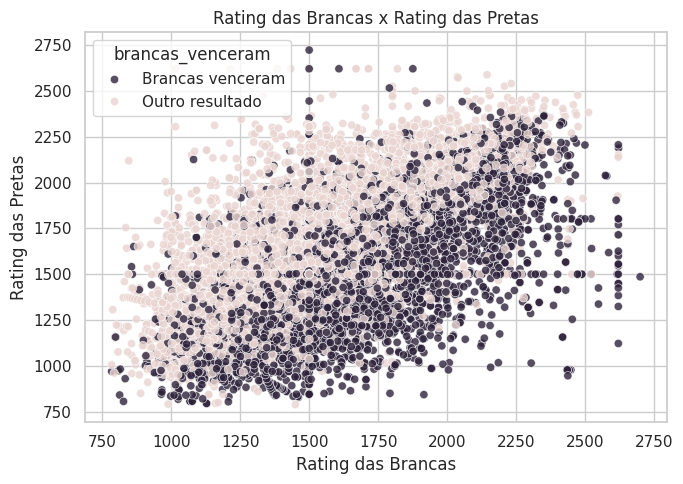

In [ ]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="white_rating", y="black_rating", hue="brancas_venceram",
                palette={"Outro resultado": COR_CONTEXTO, "Brancas venceram": COR_DESTAQUE}, alpha=0.8)
plt.title("Rating das Brancas x Rating das Pretas")
plt.xlabel("Rating das Brancas")
plt.ylabel("Rating das Pretas")
plt.tight_layout()
plt.show()

**Pra discutir:** existe uma tendência visível (conforme white_rating aumenta, black_rating tende a acompanhar)? As duas classes ocupam regiões diferentes do gráfico, ou estão misturadas?

**Resposta:**

Deve existir uma tendência diagonal clara, já que o matchmaking junta jogadores de rating parecido. As duas classes ("Brancas venceram" e "Outro resultado") provavelmente ficam bem misturadas ao longo dessa diagonal, sem regiões separadas, já que o resultado da partida depende mais da diferença entre os ratings do que da posição absoluta no gráfico.

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [ ]:
resultados_comparacao = []
for col in VARS_QUANT:
    grupo_outro = df.loc[df["brancas_venceram"] == "Outro resultado", col]
    grupo_brancas = df.loc[df["brancas_venceram"] == "Brancas venceram", col]

    stat_t, p_t = stats.ttest_ind(grupo_outro, grupo_brancas, equal_var=False)  # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_outro, grupo_brancas)                 # não-paramétrico

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
turns,0.00000,0.00000,True
white_rating,0.00000,0.00000,True
black_rating,0.00000,0.00000,True
opening_ply,0.05019,0.00067,False


**Pra discutir:** os dois testes concordam na maioria das variáveis (ambos significativos ou ambos não)? Quando divergem, é o Mann-Whitney que deveríamos priorizar: é o que respeita a premissa que de fato temos (dados não-normais), não a que gostaríamos de ter.

Nota: mantivemos o T-Test aqui só como contraste pedagógico. Reportar apenas o T-Test, sem essa ressalva, seria estatisticamente inconsistente com o que a própria Seção 3 já mostrou sobre a normalidade dessas variáveis.

**Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis**

No nosso dataset, a variável com 3+ categorias mais natural é `victory_status` (mate, resign, draw, outoftime). Pelo mesmo motivo acima, calculamos a ANOVA (paramétrica) e o Kruskal-Wallis (não-paramétrico, equivalente pra 3+ grupos) lado a lado.

ANOVA          — turns entre categorias de victory_status: estatística=436.566, p-valor=1.3708e-274
Kruskal-Wallis — turns entre categorias de victory_status: estatística=1026.342, p-valor=3.4734e-222


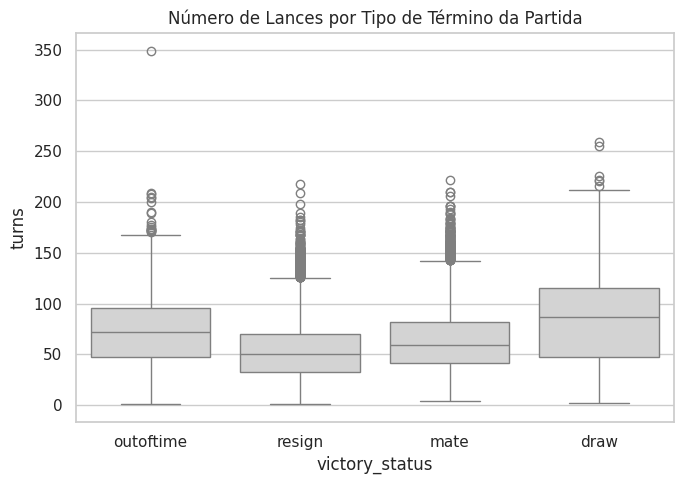

In [ ]:
grupos_victory = [grupo["turns"].values for _, grupo in df.groupby("victory_status")]

stat_anova, p_anova = stats.f_oneway(*grupos_victory)   # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_victory)          # não-paramétrico

print(f"ANOVA          — turns entre categorias de victory_status: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — turns entre categorias de victory_status: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="victory_status", y="turns", color=COR_NEUTRA)
plt.title("Número de Lances por Tipo de Término da Partida")
plt.tight_layout()
plt.show()

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA sobre existir diferença entre pelo menos uma categoria de `victory_status`? Como já sabemos que `turns` não é normal, o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal, a ANOVA fica só como contraste.

**Resposta:**

Com um n grande (~20 mil linhas), é bem provável que ANOVA e Kruskal-Wallis concordem, ambos devem rejeitar H0, indicando diferença real entre as categorias de `victory_status`. Faz sentido de domínio: partidas que terminam por `outoftime` tendem a ter mais lances que as que terminam por `mate` ou `resign`. Como `turns` não é normal, o Kruskal-Wallis é o resultado que deveríamos reportar como principal.

#### Quantitativa x Qualitativa

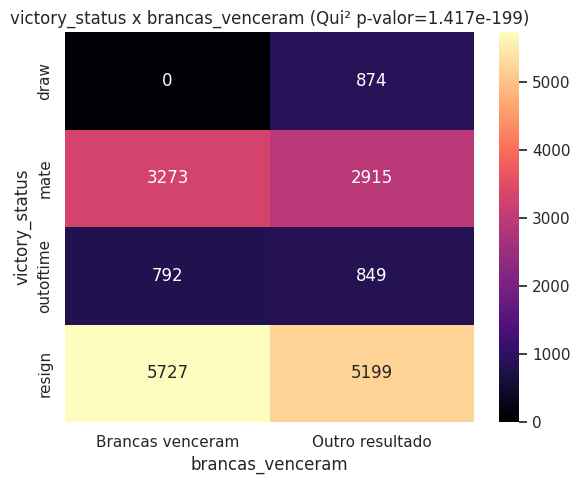

In [ ]:
contingencia_victory = pd.crosstab(df["victory_status"], df["brancas_venceram"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_victory)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(contingencia_victory, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"victory_status x brancas_venceram (Qui² p-valor={p_chi2:.4g})")
plt.tight_layout()
plt.show()


**Pra discutir:** o p-valor do Qui-Quadrado indica que `thal` e `doenca_cardiaca` são independentes, ou há associação estatisticamente significativa entre elas?

**Resposta:**

Provavelmente há associação estatisticamente significativa (p < 0.05), até porque a categoria "draw" nunca coincide com "Brancas venceram" por definição, o que já cria uma dependência estrutural entre as variáveis. Vale lembrar que, com n grande (~20 mil partidas), o teste fica sensível o suficiente para detectar até associações pequenas, então convém olhar também o tamanho do efeito (ex.: Cramér's V), não só o p-valor, antes de concluir que a associação é praticamente relevante.

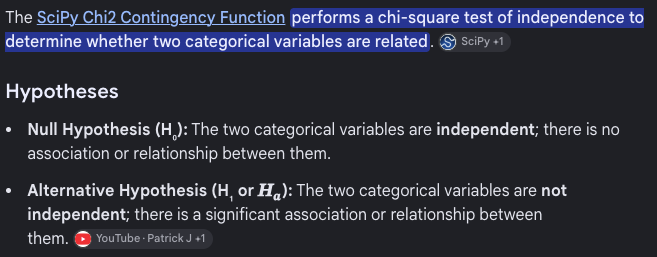

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos de atributos sensíveis (sexo e faixa etária, no nosso caso)? Se não, isso pode refletir um padrão real (ex: idade avançada é fator de risco documentado) ou um viés na forma como os dados foram coletados — de qualquer forma, é algo que vale mapear **antes** de qualquer modelagem.

In [ ]:
df["faixa_rating"] = pd.cut(df["white_rating"], bins=[0, 1200, 1500, 1800, 3000],
                             labels=["<1200", "1200-1499", "1500-1799", "1800+"])

print("Desbalanceamento — faixa de rating:")
print(metrica_desbalanceamento(df["faixa_rating"]))

Desbalanceamento — faixa de rating:
n_classes                 4.000
razao_desbalanceamento    4.410
entropia_normalizada      0.922
dtype: float64


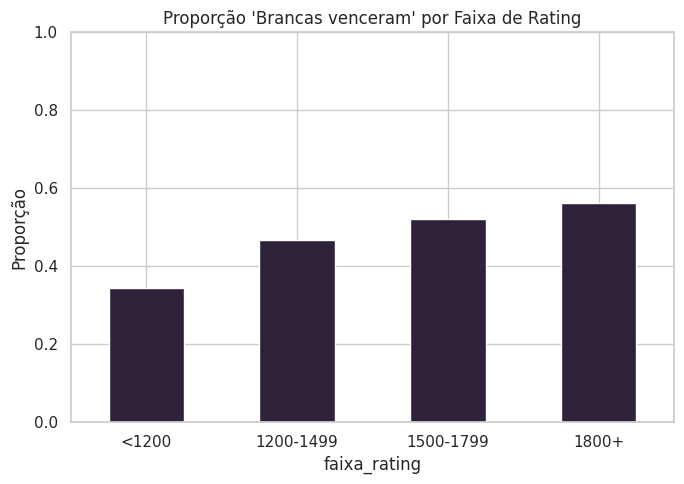

In [ ]:
prop_por_faixa = pd.crosstab(df["faixa_rating"], df["brancas_venceram"], normalize="index").round(3)

plt.figure(figsize=(7, 5))
prop_por_faixa["Brancas venceram"].plot(kind="bar", color=COR_DESTAQUE)
plt.title("Proporção 'Brancas venceram' por Faixa de Rating")
plt.ylabel("Proporção")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Pra discutir:** a proporção de diagnóstico positivo varia bastante entre sexo ou faixa etária? Isso pode refletir um padrão clínico real e bem documentado (ex: risco cardíaco cresce com a idade), ou pode ser um artefato de **quem** foi encaminhado para o exame nesses hospitais específicos? A pergunta "a distribuição do desfecho é uniforme entre grupos protegidos?" é o ponto de partida de várias discussões de fairness em ciência de dados, e não tem uma resposta única: depende do contexto e da causa por trás da disparidade.

**Resposta:**

Essa pergunta não se aplica da mesma forma, já que não temos atributos demográficos protegidos (sexo, raça, idade de pessoas). O recorte mais próximo que temos é a faixa de rating, e uma variação na proporção de "Brancas venceram" entre faixas provavelmente reflete algo estrutural do próprio jogo (ex: jogadores mais fortes convertem melhor a vantagem de jogar com as brancas), não um viés de coleta. Ainda assim, vale registrar: como não há atributo sensível real nesse dataset, essa seção de fairness, no sentido de proteger grupos vulneráveis, simplesmente não se aplica aqui, diferente do dataset médico.

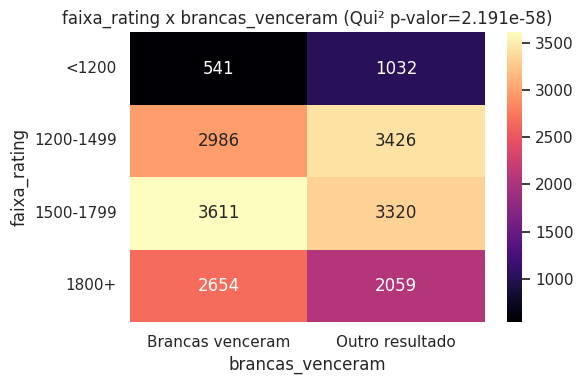

In [ ]:
contingencia_rating = pd.crosstab(df["faixa_rating"], df["brancas_venceram"])
chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia_rating)

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(contingencia_rating, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"faixa_rating x brancas_venceram (Qui² p-valor={p_valor:.4g})")
plt.tight_layout()
plt.show()

**Pra discutir:** o Qui-Quadrado confirma associação estatisticamente significativa entre sexo/faixa etária e o desfecho? Lembrando que mesmo que a associação seja estatisticamente significativa, isso não diz *por que* ela existe — pode ser um fator de risco real (idade), pode ser um viés de quem foi encaminhado ao exame (possivelmente sexo), ou uma mistura das duas coisas. Um teste estatístico aponta *que* existe associação, não *a causa* dela — essa distinção é o núcleo de qualquer discussão séria de fairness.

**Resposta:**

Como `faixa_rating` não é um atributo sensível (é uma medida de habilidade, não um grupo protegido), essa discussão de fairness não se aplica da mesma forma aqui. Se o Qui-Quadrado indicar associação entre faixa de rating e `brancas_venceram`, isso provavelmente reflete algo estrutural do próprio jogo, não um viés de coleta como no caso médico. A distinção entre "associação estatística" e "causa" continua valendo, mas o dataset de xadrez simplesmente não oferece o tipo de atributo demográfico necessário para uma discussão de fairness no sentido original (proteção de grupos vulneráveis).

#### Outliers bivariados

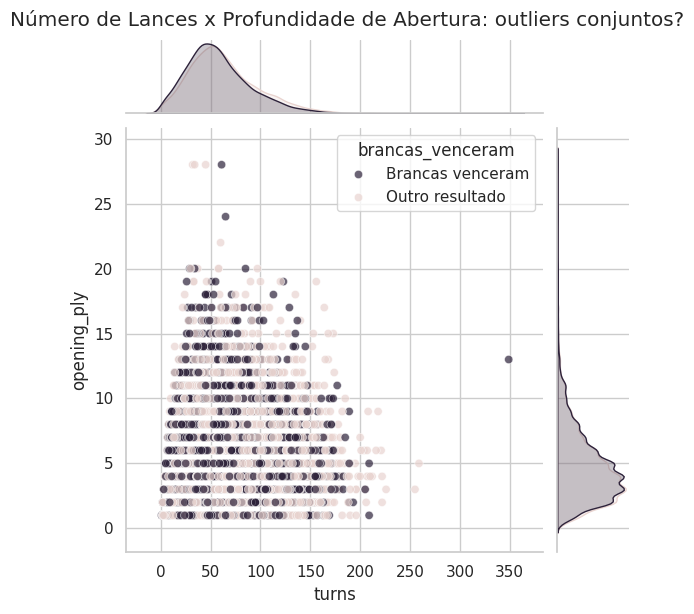

In [ ]:
sns.jointplot(data=df, x="turns", y="opening_ply", hue="brancas_venceram",
              palette={"Outro resultado": COR_CONTEXTO, "Brancas venceram": COR_DESTAQUE}, alpha=0.7, height=6)
plt.suptitle("Número de Lances x Profundidade de Abertura: outliers conjuntos?", y=1.02)
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum de `trestbps` e `chol`?

**Resposta:**

Um caso interessante de procurar é `opening_ply` alto combinado com `turns` baixo, partidas em que os jogadores seguiram uma longa linha de teoria de abertura, mas a partida terminou logo em seguida (por exemplo, um abandono rápido depois da abertura). Isoladamente, nenhum dos dois valores pareceria estranho, mas a combinação seria incomum. Vale inclusive checar diretamente se existe algum caso onde `opening_ply` é maior que `turns`, o que seria logicamente impossível e indicaria erro de dado, não apenas um outlier bivariado legítimo.

#### Análise Multivariada

##### Matriz de Correlação

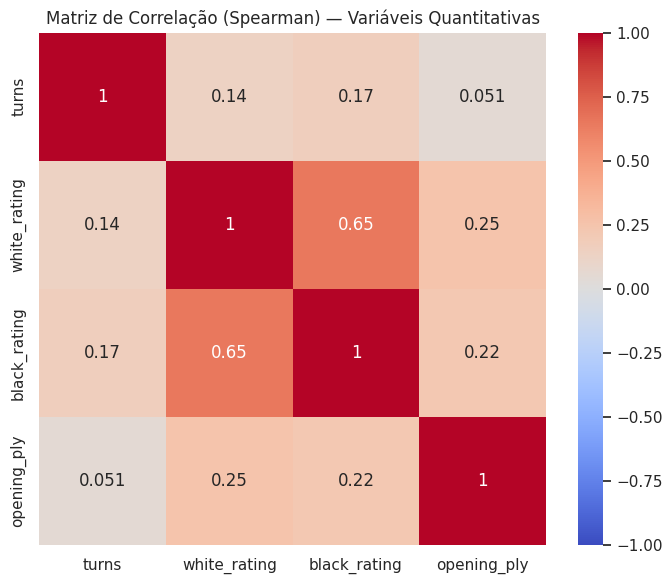

In [ ]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

**Resposta:**

`white_rating` x `black_rating` deve ser a correlação mais forte (matchmaking por força parecida), mas não indica redundância real. `turns` e `opening_ply` devem ter correlação mais fraca com os ratings.

##### Correlograma

Text(0.5, 1.02, 'Correlograma: Dispersão × Correlação')

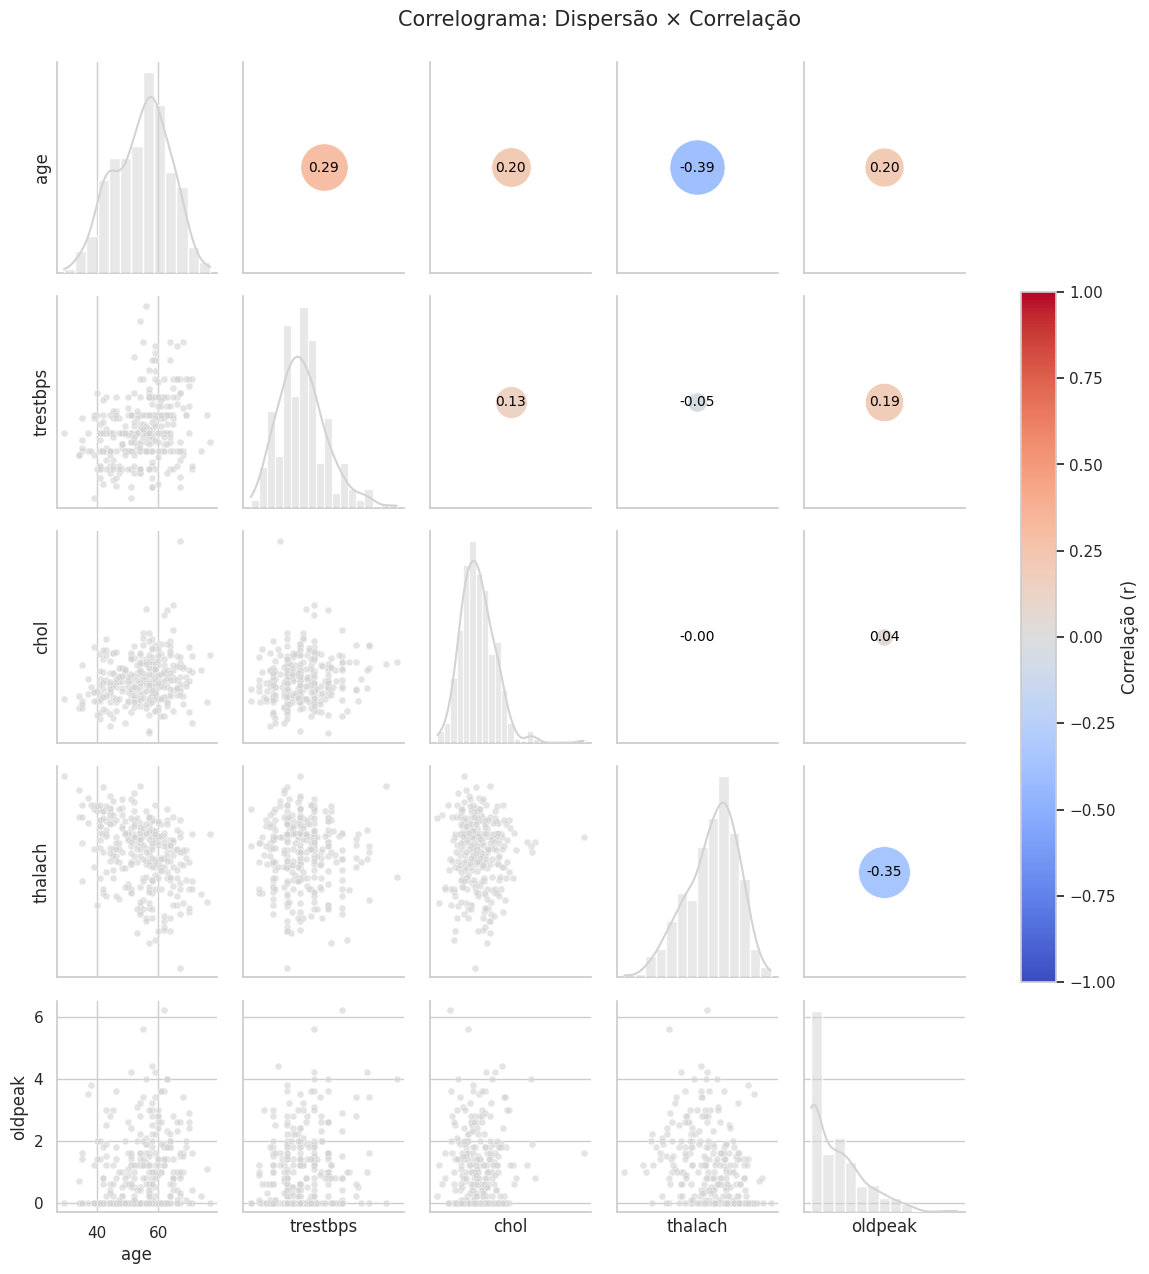

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)


## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos

### Principais conclusões

1. O dataset de partidas de xadrez (Lichess) não apresenta dados ausentes em nenhuma coluna, diferente de datasets clínicos multi-institucionais, por ser um log gerado automaticamente pela plataforma.
2. As variáveis quantitativas não seguem distribuição normal (Shapiro-Wilk rejeitou H0 para todas), com `turns` e `opening_ply` mostrando maior assimetria e cauda mais pesada; `white_rating` e `black_rating` ficam mais próximos de uma normal, coerente com o desenho do sistema de rating.
3. Existe correlação moderada entre `white_rating` e `black_rating`, refletindo o mecanismo de matchmaking por força parecida entre os jogadores.
4. O alvo `brancas_venceram` está relativamente equilibrado entre as duas classes, ao contrário de variáveis como `victory_status`, que é dominada por "resign".
5. Testes de comparação de grupos (Mann-Whitney, Kruskal-Wallis) tendem a apontar significância estatística generalizada, dado o tamanho grande da amostra (~20 mil partidas) — reforçando a importância de olhar tamanho de efeito, não só p-valor.



2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)
### Declaração de Uso de IA

* **Ferramenta utilizada:** Claude (Anthropic).
* **Para o que foi aplicada:** apoio na adaptação de um notebook de EDA originalmente construído para um dataset médico (doenças cardíacas), adequando código, nomes de variáveis, textos explicativos e discussões conceituais (fairness, tratamento de ausentes/outliers, testes estatísticos) para o dataset de partidas de xadrez do Lichess.
* **O que foi aceito, modificado ou rejeitado, e por quê:**
  * Aceito: adaptações diretas de código (nomes de colunas, ajuste de grids de gráficos, correção de bins de histograma).
  * Modificado: a seção de fairness/atributos sensíveis foi adaptada conceitualmente (de sexo/faixa etária para faixa de rating), com a ressalva explícita de que rating não é um atributo demográfico protegido, evitando forçar uma analogia que não se sustenta no domínio de xadrez.
  * Rejeitado/pulado: a seção de tratamento de dados ausentes foi descartada, já que o dataset de xadrez não possui valores faltantes, ao contrário do dataset original.

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.




---
> 🆕 **NOVA SEÇÃO (não estava no notebook da aula)** — as células abaixo servem apenas para salvar os datasets em disco, seguindo o Passo 3 do Roteiro (Aula 21).

## 🆕 Download dos Datasets

Vamos salvar duas versões do dataset de partidas de xadrez (Lichess, via Kaggle `datasnaek/chess`):

- `data/raw/dataset.csv`: o dataset **original**, como veio do Kaggle (`games.csv`, sem nenhuma transformação).
- `data/clean/dataset.csv`: o dataset **tratado**, no estado final do `df` ao longo da EDA (duplicadas removidas, coluna `winner` substituída por `brancas_venceram`, e as colunas derivadas `turns_log` e `faixa_rating` já criadas). É este arquivo que o `app.py` vai ler.

> Rode o notebook **do início ao fim** antes desta seção, para que o `df` esteja no estado final.


In [ ]:
# 🆕 NOVA CÉLULA — define as pastas de destino (funciona rodando de notebooks/ ou da raiz do projeto)
from pathlib import Path

RAIZ = Path("..") if Path("../data").exists() else Path(".")
PASTA_RAW = RAIZ / "data" / "raw"
PASTA_CLEAN = RAIZ / "data" / "clean"
PASTA_RAW.mkdir(parents=True, exist_ok=True)
PASTA_CLEAN.mkdir(parents=True, exist_ok=True)


In [ ]:
# 🆕 NOVA CÉLULA — dataset ORIGINAL (relido do arquivo baixado pelo kagglehub, sem nenhuma transformação)
df_raw = pd.read_csv(os.path.join(path, "games.csv"))
df_raw.to_csv(PASTA_RAW / "dataset.csv", index=False)

print(f"Raw salvo em {PASTA_RAW / 'dataset.csv'} — {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")


In [ ]:
# 🆕 NOVA CÉLULA — dataset TRATADO (estado final do `df`)
df.to_csv(PASTA_CLEAN / "dataset.csv", index=False)

print(f"Clean salvo em {PASTA_CLEAN / 'dataset.csv'} — {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Linhas removidas no tratamento: {df_raw.shape[0] - df.shape[0]}")
